# Signals for Next Season — 2026 → 2027 hitter study

**Which hitters should a resource-constrained MLB team investigate for 2027?**

Analytical question: *Do underlying skill levels and annual changes improve next-season batting forecasts and breakout-retention assessment beyond traditional results?*

**실행:** Runtime → Run all / 런타임 → 모두 실행. 실행된 출력이 이미 저장돼 있어 열자마자 결과를 읽을 수 있습니다. 각 코드 셀은 `[1/8]`–`[8/8]` 진행 표시와 표·그림 또는 결과를 출력합니다. ZIP 업로드·API 키·인터넷은 필요하지 않습니다.

**결론:** 현재 skill levels는 유지 구분의 정보를 더했으나 변화의 추가 효과는 작고 불안정했습니다. 실제 신호 screen의 과거 성장 성공은 M1 단독보다 낮았습니다. M1을 기준 자료로 두고 5명 신호 목록은 우월성이 미입증된 실험적 가설로 공개합니다. 이 연간 분석은 시즌 중 발견 시점 우위를 검증하지 않습니다. 2027 실제 성과는 pending입니다.

Juhan Youn · Frozen 2026 full regular-season snapshot.

In [1]:
print('[1/8] 시작: 분석 환경을 불러옵니다.', flush=True)
import base64,gzip,io,json,html,zipfile
from pathlib import Path
from datetime import datetime,timezone
import numpy as np
import pandas as pd
from IPython.display import display,HTML,Markdown,Image,FileLink
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score,balanced_accuracy_score
pd.set_option('display.max_columns',16)
print('[1/8] 완료: Run all로 표·그림·최종 보고서까지 실행합니다.', flush=True)

[1/8] 시작: 분석 환경을 불러옵니다.
[1/8] 완료: Run all로 표·그림·최종 보고서까지 실행합니다.


## 1. Validated processed snapshot

공식 원본을 대조한 처리 데이터가 이 셀에 들어 있습니다. 원본 재조회·정합성 코드는 전체 ZIP에 있습니다. 여기서는 같은 입력으로 연도별 모델, 성능, 선택 규칙, 2027 전망을 다시 계산합니다. 원본 조회시각을 이번 재실행시각으로 바꾸지 않습니다.

In [2]:
SNAPSHOT_GZIP_B64 = "..."
loaded=json.loads(gzip.decompress(base64.b64decode(SNAPSHOT_GZIP_B64)))
features=pd.read_csv(io.StringIO(loaded['features']))
manifest=json.loads(loaded['manifest'])
assert features.season.max()==2026
assert features.loc[features.season.eq(2026),'target_woba'].isna().all()
assert features.loc[features.season.eq(2026),'target_pa'].isna().all()
assert int(features.eligible_pair.sum())==1806
print('데이터 고정:',manifest['as_of_utc'])
print('2026 전체 정규시즌 입력. 2027 결과는 없고 298명의 전망 입력이 있습니다.')
display(pd.read_csv(io.StringIO(loaded['audit'])).tail(4))
print('[2/8] 완료: 검증된 처리 데이터를 준비했습니다.',flush=True)

데이터 고정: 2026-10-02T21:30:13.250258+00:00
2026 전체 정규시즌 입력. 2027 결과는 없고 298명의 전망 입력이 있습니다.
[2/8] 완료: 검증된 처리 데이터를 준비했습니다.


,season,players,pa,eligible_200pa,official_expected_reconciliation,low_pa_xwoba_rounding_differences
8,2023,656,184104,362,True,0
9,2024,651,182449,365,True,0
10,2025,673,182926,348,True,0
11,2026,662,183849,361,True,0


## 2. Nested models and chronological evaluation

M1: 전통적 성적·나이·이전 기록. M2: M1 + 현재 Statcast 수준. M3: M2 + 전년 대비 변화. 각 테스트에서 학습의 목표 연도는 반드시 테스트 목표 연도보다 이전입니다. 고정 Ridge α=10, 학습 내 대치·표준화.

In [3]:
TRAD=['woba', 'prior_woba', 'age', 'age_squared', 'pa', 'prior_pa', 'k_percent', 'bb_percent', 'iso']
SKILLS=['xwoba', 'barrel_pct', 'hardhit_pct', 'exit_velocity', 'chase_pct', 'whiff_pct']
CHANGE=['delta_xwoba', 'delta_barrel_pct', 'delta_hardhit_pct', 'delta_exit_velocity', 'delta_chase_pct', 'delta_whiff_pct']
MODELS={'M1_results': ['woba', 'prior_woba', 'age', 'age_squared', 'pa', 'prior_pa', 'k_percent', 'bb_percent', 'iso'], 'M2_levels': ['woba', 'prior_woba', 'age', 'age_squared', 'pa', 'prior_pa', 'k_percent', 'bb_percent', 'iso', 'xwoba', 'barrel_pct', 'hardhit_pct', 'exit_velocity', 'chase_pct', 'whiff_pct'], 'M3_changes': ['woba', 'prior_woba', 'age', 'age_squared', 'pa', 'prior_pa', 'k_percent', 'bb_percent', 'iso', 'xwoba', 'barrel_pct', 'hardhit_pct', 'exit_velocity', 'chase_pct', 'whiff_pct', 'delta_xwoba', 'delta_barrel_pct', 'delta_hardhit_pct', 'delta_exit_velocity', 'delta_chase_pct', 'delta_whiff_pct']}
DEV_YEARS=[2022, 2023, 2024, 2025]
ALPHA=10.0
ROB_MODELS=['M1_results', 'M2_levels', 'M3_changes']
RISES=[0.01, 0.02, 0.03]
LOSSES=[0.0, 0.01, 0.02]
TARGET_PA=[100, 200, 300, 400]
from itertools import product
from scipy.stats import hypergeom,spearmanr

def fit_model(train,features):
    model=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),Ridge(alpha=ALPHA))
    model.fit(train[features].to_numpy(dtype=float),train.target_woba.to_numpy(dtype=float))
    return model


def evaluate(features):
    pieces=[];coef=[]
    for year in DEV_YEARS+[2026]:
        train=features.loc[features.eligible_pair&features.target_season.lt(year)]
        test=features.loc[features.eligible&features.target_season.eq(year)].copy()
        assert train.target_season.max()<year
        test['p_B0_carry']=test.woba
        test['evaluation_scope']='final_2026' if year==2026 else 'development'
        test['train_n']=len(train)
        for name,cols in MODELS.items():
            model=fit_model(train,cols)
            test['p_'+name]=model.predict(test[cols].to_numpy(dtype=float))
            for col,value in zip(cols,model.named_steps['ridge'].coef_):
                coef.append({'target_year':year,'model':name,'feature':col,'standardized_coefficient':float(value)})
        pieces.append(test)
    return pd.concat(pieces,ignore_index=True),pd.DataFrame(coef)


def metric_table(predictions):
    rows=[]
    scopes={'development':predictions.loc[predictions.evaluation_scope.eq('development')], 'final_2026':predictions.loc[predictions.target_season.eq(2026)],'without_2022':predictions.loc[predictions.target_season.isin([2023,2024,2025])]}
    scopes.update({str(year):predictions.loc[predictions.target_season.eq(year)] for year in DEV_YEARS})
    for scope,frame in scopes.items():
        frame=frame.loc[frame.target_available]
        for name in ['B0_carry']+list(MODELS):
            p=frame['p_'+name];y=frame.target_woba
            rows.append({'scope':scope,'model':name,'n':len(frame),'rmse':float(np.sqrt(np.mean((y-p)**2))),'mae':float(np.mean(np.abs(y-p))),'pa_weighted_rmse':float(np.sqrt(np.average((y-p)**2,weights=frame.target_pa)))})
    return pd.DataFrame(rows)


def selection_rule(metrics):
    dev=metrics.loc[metrics.scope.eq('development')].set_index('model')
    final=metrics.loc[metrics.scope.eq('final_2026')].set_index('model')
    positive_years=sum(metrics.loc[(metrics.scope.eq(str(y)))&metrics.model.eq('M3_changes'),'rmse'].iloc[0]<metrics.loc[(metrics.scope.eq(str(y)))&metrics.model.eq('M2_levels'),'rmse'].iloc[0] for y in DEV_YEARS)
    changes={'development_rmse_improves':bool(dev.loc['M3_changes','rmse']<dev.loc['M2_levels','rmse']),'development_mae_improves':bool(dev.loc['M3_changes','mae']<dev.loc['M2_levels','mae']),'positive_development_years':int(positive_years),'final_2026_rmse_improves':bool(final.loc['M3_changes','rmse']<final.loc['M2_levels','rmse'])}
    support=changes['development_rmse_improves'] and changes['development_mae_improves'] and positive_years>=3 and changes['final_2026_rmse_improves']
    levels=bool(dev.loc['M2_levels','rmse']<dev.loc['M1_results','rmse'] and dev.loc['M2_levels','mae']<dev.loc['M1_results','mae'] and final.loc['M2_levels','rmse']<final.loc['M1_results','rmse'])
    selected='M3_changes' if support else ('M2_levels' if levels else 'M1_results')
    return {'selected_model':selected,'support_changes':bool(support),'changes_checks':changes,'levels_supported':levels,'selection_disclosure':'Exploratory development policy includes final-2026 performance. That comparison is not a second untouched holdout for the resulting selection.'}


def paired_gain(predictions,first,second):
    d=predictions.loc[predictions.evaluation_scope.eq('development')&predictions.target_available].copy()
    d['gain']=(d.target_woba-d['p_'+first])**2-(d.target_woba-d['p_'+second])**2
    rng=np.random.default_rng(1701)
    intervals={}
    for group in ['target_season','player_id']:
        sums=d.groupby(group)['gain'].sum().to_numpy();counts=d.groupby(group).size().to_numpy()
        indexes=rng.integers(0,len(sums),size=(3000,len(sums)))
        draws=sums[indexes].sum(axis=1)/counts[indexes].sum(axis=1)
        intervals[group]=np.quantile(draws,[.025,.975]).tolist()
    return {'comparison':first+' → '+second,'mean_squared_error_gain':float(d.gain.mean()),'exploratory_cluster_95pct_intervals':intervals,'by_target_year':{str(k):float(v) for k,v in d.groupby('target_season').gain.mean().items()}}


def decision_backtest(predictions):
    rows=[];names=[]
    for year in DEV_YEARS+[2026]:
      for pool_name,pool_column in [('modest_results','modest_results'),('discovery_pool','discovery_pool')]:
        candidates=predictions.loc[predictions.target_season.eq(year)&predictions[pool_column]]
        for name,column in {'visible_woba':'woba','xwoba':'xwoba',**{name:'p_'+name for name in MODELS}}.items():
            selected=candidates.sort_values([column,'player_id'],ascending=[False,True]).head(15).copy()
            usable=selected.target_available&selected.target_woba.ge(.330)
            valid=selected.loc[selected.target_available]
            rows.append({'target_year':year,'pool':pool_name,'method':name,'candidate_pool':len(candidates),'selected_n':len(selected),'available_200pa':int(selected.target_available.sum()),'usable_bat_successes':int(usable.sum()),'usable_bat_rate':float(usable.mean()),'mean_target_woba_available':float(valid.target_woba.mean())})
            for rank,row in enumerate(selected.itertuples(),1):
                names.append({'target_year':year,'pool':pool_name,'method':name,'rank':rank,'player_id':row.player_id,'name':row.display_name,'predictor_woba':row.woba,'predictor_xwoba':row.xwoba,'target_pa':row.target_pa,'target_woba':row.target_woba,'target_available':row.target_available,'usable_bat':bool(row.target_available and row.target_woba>=.330)})
    return pd.DataFrame(rows),pd.DataFrame(names)


def breakout_diagnostics(predictions):
    rows=[]
    for scope in ['development','final_2026']:
        d=predictions.loc[predictions.evaluation_scope.eq(scope)&predictions.target_available&predictions.delta_woba.ge(.020)]
        y=(d.target_woba>=(d.woba-.010).round(3)).astype(int)
        for name in MODELS:
            margin=d['p_'+name]-(d.woba-.010)
            rows.append({'scope':scope,'model':name,'n_apparent_breakouts':len(d),'sustained_n':int(y.sum()),'retention_margin_auc':float(roc_auc_score(y,margin)) if y.nunique()==2 else None,'threshold_accuracy':float(((margin>=0).astype(int)==y).mean()),'balanced_accuracy':float(balanced_accuracy_score(y,(margin>=0).astype(int)))})
    return pd.DataFrame(rows)


def forecast(features,predictions,policy):
    current=features.loc[features.season.eq(2026)&features.eligible].copy()
    assert current.target_woba.isna().all()
    train=features.loc[features.eligible_pair&features.target_season.le(2026)]
    for name,cols in MODELS.items():current['p_'+name]=fit_model(train,cols).predict(current[cols].to_numpy(dtype=float))
    selected=policy['selected_model']
    current['projected_woba_2027']=current['p_'+selected]
    current['projected_delta']=current.projected_woba_2027-current.woba
    current['model_spread']=current[['p_'+name for name in MODELS]].max(axis=1)-current[['p_'+name for name in MODELS]].min(axis=1)
    residuals=predictions.loc[predictions.target_available,'target_woba']-predictions.loc[predictions.target_available,'p_'+selected]
    low,high=np.quantile(residuals,[.10,.90])
    current['exploratory_80pct_low']=current.projected_woba_2027+low
    current['exploratory_80pct_high']=current.projected_woba_2027+high
    current['type']=np.where(current.delta_woba.le(-.010),'회복 후보','성장 관찰 후보')
    improving=np.column_stack([current.delta_exit_velocity.ge(.5),current.delta_barrel_pct.ge(1),current.delta_chase_pct.le(-1),current.delta_whiff_pct.le(-1)])
    current['improving_signal_count']=improving.sum(axis=1)
    current['salary_2027_status']='미확인 — 계약·옵션·영입 비용 별도 조사'
    current['created_at_utc']=datetime.now(timezone.utc).isoformat()
    watch=current.loc[current.discovery_pool].sort_values(['projected_woba_2027','player_id'],ascending=[False,True]).head(15).copy()
    watch.insert(0,'rank',np.arange(1,len(watch)+1))
    # Block-player resampling: descriptive coefficient/ranking stability, not breakout probability.
    candidate=current.loc[current.discovery_pool].copy()
    ids=train.player_id.unique();groups={pid:group for pid,group in train.groupby('player_id')}
    rng=np.random.default_rng(2027);draws=[]
    for _ in range(150):
        boot=pd.concat([groups[pid] for pid in rng.choice(ids,size=len(ids),replace=True)],ignore_index=True)
        p=fit_model(boot,MODELS[selected]).predict(candidate[MODELS[selected]].to_numpy(dtype=float))
        ranks=pd.Series(p,index=candidate.player_id).rank(ascending=False,method='first')
        draws.append(ranks)
    ranks=pd.DataFrame(draws)
    stability=pd.DataFrame({'player_id':ranks.columns,'bootstrap_top15_share':(ranks<=15).mean().to_numpy(),'bootstrap_median_rank':ranks.median().to_numpy()})
    watch=watch.merge(stability,on='player_id',validate='one_to_one')
    coverage=float(((residuals>=low)&(residuals<=high)).mean())
    return current,watch,{'residual_quantiles':[float(low),float(high)],'historical_empirical_coverage':coverage,'interpretation':'Exploratory historical error range; future calibrated coverage and breakout probability are not established.'}


def signal_count(d):
    return np.column_stack([d.delta_exit_velocity.ge(.5),d.delta_barrel_pct.ge(1),d.delta_chase_pct.le(-1),d.delta_whiff_pct.le(-1)]).sum(axis=1)


def screen(d,hidden=False):
    ok=d.discovery_pool & d.xwoba.ge(.320) & d.delta_xwoba.ge(.010) & (signal_count(d)>=2)
    if hidden:ok=ok & d.delta_woba.lt(.020)
    return ok


def retention_data(predictions,scope,rise=.020,loss=.010,pa=200,view='conditional'):
    d=predictions.loc[predictions.evaluation_scope.eq(scope)&predictions.delta_woba.ge(rise)].copy().reset_index(drop=True)
    enough=d.target_pa.ge(pa)
    retained=d.target_woba.ge((d.woba-loss).round(3))
    if view=='conditional':
        d=d.loc[enough].copy().reset_index(drop=True)
        y=d.target_woba.ge((d.woba-loss).round(3)).astype(int).to_numpy()
    else:y=(enough&retained).astype(int).to_numpy()
    scores=np.column_stack([(d['p_'+m]-(d.woba-loss)).to_numpy() for m in ROB_MODELS])
    return d,y,scores


def sensitivity(predictions,scopes=('development','final_2026')):
    rows=[]
    for scope,rise,loss,pa,view in product(scopes,RISES,LOSSES,TARGET_PA,['conditional','all_followed_composite']):
        d,y,scores=retention_data(predictions,scope,rise,loss,pa,view)
        base=predictions.loc[predictions.evaluation_scope.eq(scope)&predictions.delta_woba.ge(rise)]
        for i,m in enumerate(ROB_MODELS):
            rows.append({'scope':scope,'rise':rise,'allowed_loss':loss,'target_pa_min':pa,'view':view,'model':m,'n':len(d),'unique_players':d.player_id.nunique(),'success_n':int(y.sum()),'full_breakout_cohort_n':len(base),'insufficient_pa_n':int(base.target_pa.lt(pa).sum()),'auc':roc_auc_score(y,scores[:,i]) if len(np.unique(y))==2 else np.nan,'balanced_accuracy':balanced_accuracy_score(y,(scores[:,i]>=0).astype(int)) if len(np.unique(y))==2 else np.nan,'main_definition':rise==.020 and loss==.010 and pa==200})
    return pd.DataFrame(rows)


def auc_uncertainty(predictions,scopes=('development','final_2026')):
    auc_rows=[];difference_rows=[]
    rng=np.random.default_rng(4427)
    for scope,view in product(scopes,['conditional','all_followed_composite']):
        d,y,scores=retention_data(predictions,scope,view=view)
        ids=d.player_id.unique();group={pid:np.flatnonzero(d.player_id.to_numpy()==pid) for pid in ids}
        if len(np.unique(y))<2:
            for m in ROB_MODELS:auc_rows.append({'scope':scope,'view':view,'model':m,'n':len(d),'unique_players':len(ids),'success_n':int(y.sum()),'auc':np.nan,'low':np.nan,'high':np.nan,'valid_resamples':0})
            for first,second in [(0,1),(1,2),(0,2)]:difference_rows.append({'scope':scope,'view':view,'comparison':ROB_MODELS[second]+' minus '+ROB_MODELS[first],'auc_gain':np.nan,'low':np.nan,'high':np.nan,'n':len(d),'unique_players':len(ids),'valid_resamples':0})
            continue
        observed=np.array([roc_auc_score(y,scores[:,i]) for i in range(3)])
        draws=[]
        for _ in range(1000):
            index=np.concatenate([group[pid] for pid in rng.choice(ids,size=len(ids),replace=True)])
            if len(np.unique(y[index]))<2:continue
            draws.append([roc_auc_score(y[index],scores[index,i]) for i in range(3)])
        draws=np.array(draws)
        for i,m in enumerate(ROB_MODELS):
            lo,hi=np.quantile(draws[:,i],[.025,.975])
            auc_rows.append({'scope':scope,'view':view,'model':m,'n':len(d),'unique_players':len(ids),'success_n':int(y.sum()),'auc':observed[i],'low':lo,'high':hi,'valid_resamples':len(draws)})
        for first,second in [(0,1),(1,2),(0,2)]:
            lo,hi=np.quantile(draws[:,second]-draws[:,first],[.025,.975])
            difference_rows.append({'scope':scope,'view':view,'comparison':ROB_MODELS[second]+' minus '+ROB_MODELS[first],'auc_gain':observed[second]-observed[first],'low':lo,'high':hi,'n':len(d),'unique_players':len(ids),'valid_resamples':len(draws)})
    return pd.DataFrame(auc_rows),pd.DataFrame(difference_rows)


def decision_outcomes(d):
    enough=d.target_pa.ge(200)
    return {'growth':enough&d.target_woba.ge((d.woba+.020).round(3)), 'usable':enough&d.target_woba.ge(.330), 'available':enough}


def policy_backtest(predictions,years=(2022,2023,2024,2025,2026)):
    rows=[];names=[]
    for year,policy in product(years,['original_13','revised_hidden_5']):
        d=predictions.loc[predictions.target_season.eq(year)&predictions.discovery_pool].copy()
        hidden=policy=='revised_hidden_5'
        if hidden:d=d.loc[d.delta_woba.lt(.020)]
        s=d.loc[screen(d,hidden)]
        k=min(5 if hidden else 13,len(s))
        methods={'signal_then_M1':(s,'p_M1_results'),'signal_then_delta_xwoba':(s,'delta_xwoba'),'M1_only':(d,'p_M1_results'),'current_woba':(d,'woba'),'current_xwoba':(d,'xwoba'),'delta_xwoba':(d,'delta_xwoba')}
        for method,(pool,col) in methods.items():
            selected=pool.sort_values([col,'player_id'],ascending=[False,True]).head(k)
            outcome=decision_outcomes(selected)
            rows.append({'year':year,'policy':policy,'method':method,'base_pool_n':len(d),'screen_pool_n':len(s),'selected_n':k,'growth_successes':int(outcome['growth'].sum()),'usable_successes':int(outcome['usable'].sum()),'available_n':int(outcome['available'].sum()),'mean_woba_available':selected.loc[outcome['available'],'target_woba'].mean(),'random_growth_low':np.nan,'random_growth_high':np.nan})
            for rank,r in enumerate(selected.itertuples(),1):
                names.append({'year':year,'policy':policy,'method':method,'rank':rank,'player_id':r.player_id,'name':r.display_name,'predictor_woba':r.woba,'target_pa':r.target_pa,'target_woba':r.target_woba})
        total=decision_outcomes(d)
        random={'year':year,'policy':policy,'method':'random_expected','base_pool_n':len(d),'screen_pool_n':len(s),'selected_n':k,'mean_woba_available':np.nan}
        for key,col in [('growth','growth_successes'),('usable','usable_successes'),('available','available_n')]:
            successes=int(total[key].sum());random[col]=k*successes/len(d) if len(d) else 0
            random['random_'+key+'_low']=float(hypergeom.ppf(.025,len(d),successes,k)) if k else 0.
            random['random_'+key+'_high']=float(hypergeom.ppf(.975,len(d),successes,k)) if k else 0.
        rows.append(random)
    return pd.DataFrame(rows),pd.DataFrame(names)


def policy_summary(backtest):
    rows=[]
    for (policy,method),d in backtest.groupby(['policy','method'],sort=False):
        rows.append({'policy':policy,'method':method,'total_slots':int(d.selected_n.sum()),'growth_successes':float(d.growth_successes.sum()),'usable_successes':float(d.usable_successes.sum()),'available_n':float(d.available_n.sum()),'years':len(d)})
    return pd.DataFrame(rows)


def ranking_churn(predictions,current):
    rows=[];names=[]
    periods={str(year):predictions.loc[predictions.target_season.eq(year)&predictions.discovery_pool] for year in [2022,2023,2024,2025,2026]}
    periods['2027_forecast']=current.loc[current.discovery_pool]
    for year,d in periods.items():
        ranks={m:d.sort_values(['p_'+m,'player_id'],ascending=[False,True]).reset_index(drop=True) for m in ROB_MODELS}
        for k,first,second in product([5,15],ROB_MODELS,ROB_MODELS):
            if (first,second) not in [('M1_results','M2_levels'),('M2_levels','M3_changes'),('M1_results','M3_changes')]:continue
            a=ranks[first].head(k);b=ranks[second].head(k);a_ids=set(a.player_id);b_ids=set(b.player_id)
            ra=ranks[first].assign(rank=np.arange(1,len(d)+1)).set_index('player_id')['rank']
            rb=ranks[second].assign(rank=np.arange(1,len(d)+1)).set_index('player_id')['rank'].reindex(ra.index)
            rows.append({'period':year,'k':k,'comparison':second+' vs '+first,'pool_n':len(d),'replacements':len(b_ids-a_ids),'jaccard':len(a_ids&b_ids)/len(a_ids|b_ids),'mean_absolute_rank_change':float(np.abs(ra-rb).mean()),'rank_spearman':spearmanr(ra,rb).statistic})
            for kind,group in [('added',b.loc[b.player_id.isin(b_ids-a_ids)]),('removed',a.loc[a.player_id.isin(a_ids-b_ids)])]:
                for r in group.itertuples():names.append({'period':year,'k':k,'comparison':second+' vs '+first,'change':kind,'player_id':r.player_id,'name':r.display_name})
    return pd.DataFrame(rows),pd.DataFrame(names)


def sensitivity_summary(s):
    rows=[]
    for (scope,view),d in s.groupby(['scope','view']):
        p=d.pivot(index=['rise','allowed_loss','target_pa_min'],columns='model',values='auc')
        for first,second in [('M1_results','M2_levels'),('M2_levels','M3_changes'),('M1_results','M3_changes')]:
            change=(p[second]-p[first]).dropna()
            rows.append({'scope':scope,'view':view,'comparison':second+' minus '+first,'definitions':len(change),'positive_definitions':int(change.gt(0).sum()),'min_auc_gain':change.min(),'median_auc_gain':change.median(),'max_auc_gain':change.max()})
    return pd.DataFrame(rows)

print('[3/8] 완료: 학습·검증·전망 함수를 정의했습니다.',flush=True)
print('목표 시즌 순서를 지켜 평가하며, 입력에 미래 target 변수를 쓰지 않습니다.')

[3/8] 완료: 학습·검증·전망 함수를 정의했습니다.
목표 시즌 순서를 지켜 평가하며, 입력에 미래 target 변수를 쓰지 않습니다.


## 3. Primary and secondary results

전체 예측의 RMSE/MAE가 주 분석입니다. 이미 오른 타자의 유지 여부 AUC는 보조 분석입니다. 작은 차이를 큰 효과라고 해석하지 않습니다.

[4/8] 실행 중: 연도별 미래 예측을 다시 계산합니다.
현재 Skill levels는 유지 여부 구분의 단서. 변화의 추가 효과는 작고 일관적이지 않습니다.
보수적 공식 모델: M1_results
[4/8] 완료: 저장된 기준 결과와 수치가 일치합니다.


,scope,model,n,rmse,mae,pa_weighted_rmse
0,development,B0_carry,889,0.03839,0.03031,0.03698
1,development,M1_results,889,0.03201,0.02537,0.03058
2,development,M2_levels,889,0.03185,0.02538,0.03023
3,development,M3_changes,889,0.03168,0.02521,0.03010
4,final_2026,B0_carry,229,0.03730,0.02961,0.03635
5,final_2026,M1_results,229,0.03075,0.02422,0.03004
6,final_2026,M2_levels,229,0.02972,0.02393,0.02890
7,final_2026,M3_changes,229,0.02980,0.02399,0.02907


,scope,model,n_apparent_breakouts,sustained_n,retention_margin_auc,threshold_accuracy,balanced_accuracy
0,development,M1_results,250,85,0.724,0.708,0.636
1,development,M2_levels,250,85,0.765,0.736,0.697
2,development,M3_changes,250,85,0.774,0.728,0.688
3,final_2026,M1_results,66,25,0.687,0.682,0.642
4,final_2026,M2_levels,66,25,0.763,0.697,0.670
5,final_2026,M3_changes,66,25,0.782,0.742,0.707


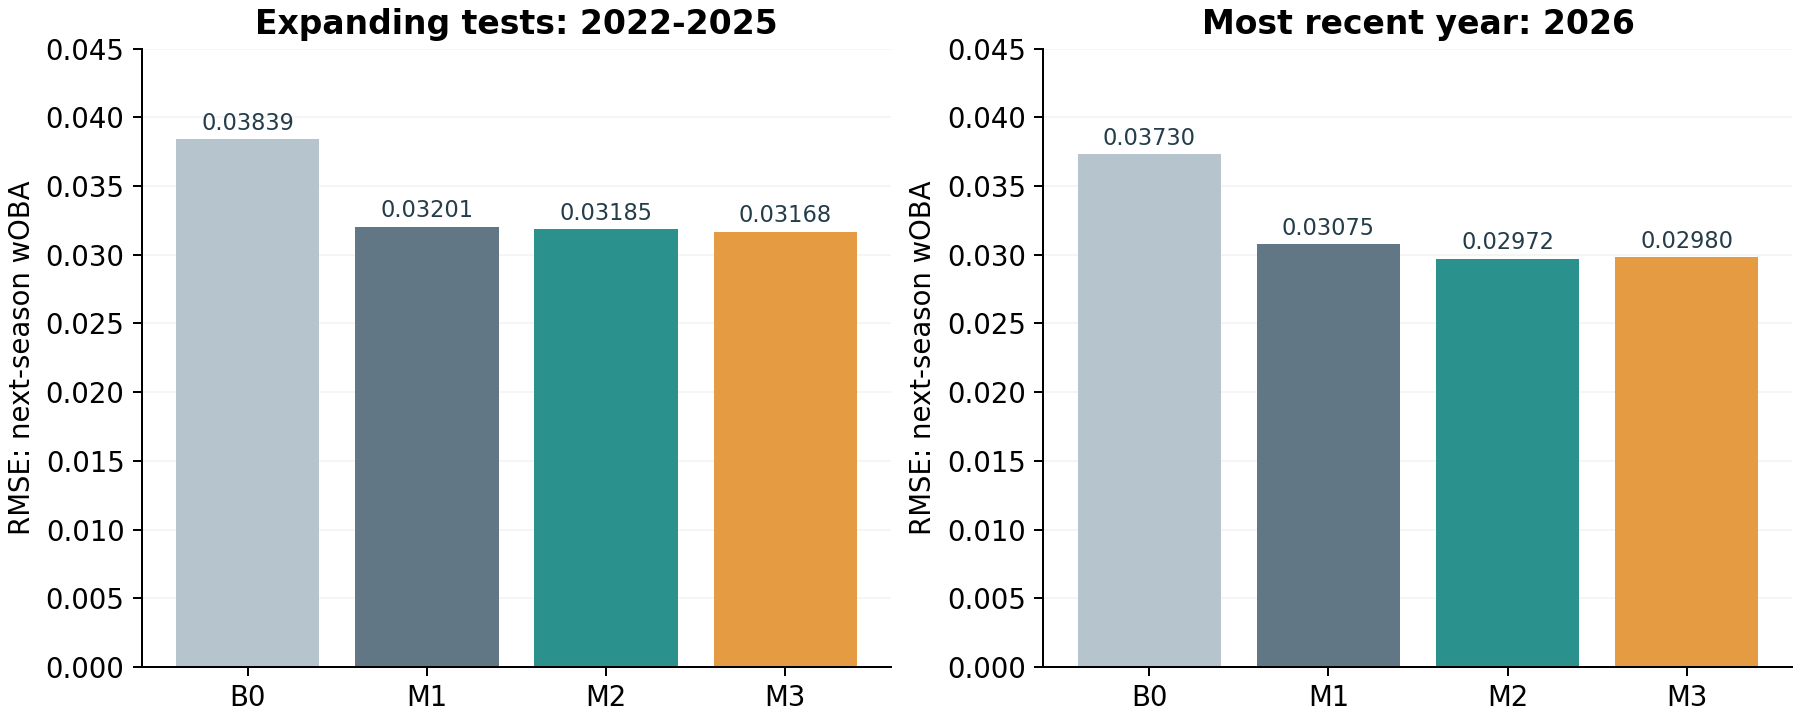

In [4]:
print('[4/8] 실행 중: 연도별 미래 예측을 다시 계산합니다.',flush=True)
predictions,coefficients=evaluate(features)
metrics=metric_table(predictions)
policy=selection_rule(metrics)
gold=pd.read_csv(io.StringIO(loaded['gold_metrics']))
assert np.allclose(metrics[['rmse','mae','pa_weighted_rmse']],gold[['rmse','mae','pa_weighted_rmse']],atol=1e-10,rtol=0)
assert policy['selected_model']=='M1_results'
diagnostics=breakout_diagnostics(predictions)
display(metrics.loc[metrics.scope.isin(['development','final_2026'])].round(5))
display(diagnostics.round(3))
display(Image(data=base64.b64decode(loaded['charts']['model_comparison.png'])))
print('현재 Skill levels는 유지 여부 구분의 단서. 변화의 추가 효과는 작고 일관적이지 않습니다.')
print('보수적 공식 모델:',policy['selected_model'])
print('[4/8] 완료: 저장된 기준 결과와 수치가 일치합니다.',flush=True)

## 4. Decision backtest and uncertainty

모든 선택을 분모에 포함합니다. 성장 성공 = 다음 해 200PA 이상·wOBA +.020 이상. 유용 타자 성공 = 200PA 이상·wOBA .330 이상. 신호 조사 정책을 동일 pool·동일 예산의 단순·무작위 기준과 따로 비교하며, 이미 관측한 결과이므로 탐색적 평가입니다.

In [5]:
print('[5/8] 실행 중: 민감도·군집 AUC·동일 예산 정책을 다시 계산합니다.',flush=True)
backtest,backtest_names=decision_backtest(predictions)
gains=[paired_gain(predictions,'M1_results','M2_levels'),paired_gain(predictions,'M2_levels','M3_changes')]
sens=sensitivity(predictions)
auc_ci,paired_ci=auc_uncertainty(predictions)
policy_bt,policy_names=policy_backtest(predictions)
policy_sum=policy_summary(policy_bt)
gold_current_for_ranks=pd.read_csv(io.StringIO(loaded['gold_forecasts']))
churn,churn_names=ranking_churn(predictions,gold_current_for_ranks)
for calculated,key,columns in [(sens,'sensitivity',['auc']),(auc_ci,'auc_intervals',['auc','low','high']),(paired_ci,'paired_auc',['auc_gain','low','high']),(policy_sum,'selection',['growth_successes','usable_successes'])]:
    gold_table=pd.read_csv(io.StringIO(loaded[key]))
    assert np.allclose(calculated[columns],gold_table[columns],atol=1e-10,rtol=0,equal_nan=True)
display(auc_ci.round(3))
display(paired_ci.round(3))
display(sensitivity_summary(sens).round(3))
display(policy_sum.round(2))
display(churn.loc[churn.k.eq(15),['period','comparison','replacements']])
print('신호 screen의 성장 성공은 단순 M1보다 낮았습니다. 우월한 조사 순위로 채택하지 않습니다.')
print('모든 정책은 같은 pool·같은 k. 출전 부족도 실패로 포함합니다. 범위는 선수 군집 탐색적 범위입니다.')
print('[5/8] 완료: 모든 추가 진단이 저장된 결과와 일치합니다.',flush=True)

[5/8] 실행 중: 민감도·군집 AUC·동일 예산 정책을 다시 계산합니다.
신호 screen의 성장 성공은 단순 M1보다 낮았습니다. 우월한 조사 순위로 채택하지 않습니다.
모든 정책은 같은 pool·같은 k. 출전 부족도 실패로 포함합니다. 범위는 선수 군집 탐색적 범위입니다.
[5/8] 완료: 모든 추가 진단이 저장된 결과와 일치합니다.


,scope,view,model,n,unique_players,success_n,auc,low,high,valid_resamples
0,development,conditional,M1_results,250,206,85,0.724,0.654,0.786,1000
1,development,conditional,M2_levels,250,206,85,0.765,0.695,0.827,1000
2,development,conditional,M3_changes,250,206,85,0.774,0.705,0.836,1000
3,development,all_followed_composite,M1_results,292,243,85,0.694,0.624,0.760,1000
4,development,all_followed_composite,M2_levels,292,243,85,0.732,0.664,0.798,1000
5,development,all_followed_composite,M3_changes,292,243,85,0.743,0.674,0.811,1000
6,final_2026,conditional,M1_results,66,66,25,0.687,0.552,0.815,1000
7,final_2026,conditional,M2_levels,66,66,25,0.763,0.637,0.876,1000
8,final_2026,conditional,M3_changes,66,66,25,0.782,0.668,0.893,1000
9,final_2026,all_followed_composite,M1_results,86,86,25,0.648,0.518,0.773,1000


,scope,view,comparison,auc_gain,low,high,n,unique_players,valid_resamples
0,development,conditional,M2_levels minus M1_results,0.041,0.013,0.067,250,206,1000
1,development,conditional,M3_changes minus M2_levels,0.009,-0.006,0.025,250,206,1000
2,development,conditional,M3_changes minus M1_results,0.050,0.018,0.078,250,206,1000
3,development,all_followed_composite,M2_levels minus M1_results,0.038,0.012,0.065,292,243,1000
4,development,all_followed_composite,M3_changes minus M2_levels,0.011,-0.004,0.026,292,243,1000
5,development,all_followed_composite,M3_changes minus M1_results,0.049,0.021,0.078,292,243,1000
6,final_2026,conditional,M2_levels minus M1_results,0.076,0.004,0.149,66,66,1000
7,final_2026,conditional,M3_changes minus M2_levels,0.020,-0.022,0.067,66,66,1000
8,final_2026,conditional,M3_changes minus M1_results,0.096,0.009,0.181,66,66,1000
9,final_2026,all_followed_composite,M2_levels minus M1_results,0.063,0.001,0.134,86,86,1000


,scope,view,comparison,definitions,positive_definitions,min_auc_gain,median_auc_gain,max_auc_gain
0,development,all_followed_composite,M2_levels minus M1_results,36,36,0.017,0.033,0.052
1,development,all_followed_composite,M3_changes minus M2_levels,36,33,-0.003,0.006,0.017
2,development,all_followed_composite,M3_changes minus M1_results,36,36,0.020,0.045,0.056
3,development,conditional,M2_levels minus M1_results,36,36,0.008,0.030,0.054
4,development,conditional,M3_changes minus M2_levels,36,29,-0.009,0.006,0.017
5,development,conditional,M3_changes minus M1_results,36,36,0.008,0.037,0.057
6,final_2026,all_followed_composite,M2_levels minus M1_results,36,36,0.011,0.046,0.079
7,final_2026,all_followed_composite,M3_changes minus M2_levels,36,23,-0.012,0.003,0.042
8,final_2026,all_followed_composite,M3_changes minus M1_results,36,36,0.014,0.047,0.119
9,final_2026,conditional,M2_levels minus M1_results,36,36,0.019,0.060,0.102


,policy,method,total_slots,growth_successes,usable_successes,available_n,years
0,original_13,signal_then_M1,53,7.00,12.00,47.00,5
1,original_13,signal_then_delta_xwoba,53,10.00,9.00,44.00,5
2,original_13,M1_only,53,13.00,19.00,47.00,5
3,original_13,current_woba,53,7.00,12.00,43.00,5
4,original_13,current_xwoba,53,12.00,17.00,51.00,5
5,original_13,delta_xwoba,53,13.00,10.00,42.00,5
6,original_13,random_expected,53,11.20,7.23,36.03,5
7,revised_hidden_5,signal_then_M1,22,2.00,6.00,19.00,5
8,revised_hidden_5,signal_then_delta_xwoba,22,4.00,5.00,20.00,5
9,revised_hidden_5,M1_only,22,7.00,9.00,21.00,5


,period,comparison,replacements
3,2022,M2_levels vs M1_results,7
4,2022,M3_changes vs M1_results,6
5,2022,M3_changes vs M2_levels,1
9,2023,M2_levels vs M1_results,4
10,2023,M3_changes vs M1_results,4
11,2023,M3_changes vs M2_levels,2
15,2024,M2_levels vs M1_results,4
16,2024,M3_changes vs M1_results,5
17,2024,M3_changes vs M2_levels,3
21,2025,M2_levels vs M1_results,6


## 5. Frozen 2027 forecasts and exploratory research queue

2027 결과는 학습·검증·후보 선택 어디에도 없습니다. 전망은 다음 시즌 충분한 MLB 타석을 얻는 조건입니다. 오차 범위는 과거 잔차 범위이며 미래 보장 구간이 아닙니다.

In [6]:
print('[6/8] 실행 중: 완료된 2026까지 학습해 2027을 전망합니다.',flush=True)
current,watch,bands=forecast(features,predictions,policy)
gold_current=pd.read_csv(io.StringIO(loaded['gold_forecasts'])).set_index('player_id')
for name in MODELS:
    assert np.allclose(current.set_index('player_id')['p_'+name],gold_current['p_'+name],atol=1e-10,rtol=0)
gold_watch=pd.read_csv(io.StringIO(loaded['gold_watch']))
assert watch.player_id.tolist()==gold_watch.player_id.tolist()
# Preserve original creation time for an unchanged snapshot replay.
current['created_at_utc']=current.player_id.map(gold_current.created_at_utc)
watch['created_at_utc']=watch.player_id.map(gold_current.created_at_utc)
queue=current.loc[screen(current,hidden=True)].sort_values(['projected_woba_2027','player_id'],ascending=[False,True]).copy()
gold_queue=pd.read_csv(io.StringIO(loaded['gold_queue']))
assert queue.player_id.tolist()==gold_queue.player_id.tolist()
queue=gold_queue.copy()
display(queue[['queue_order','display_name','pa','woba','xwoba','delta_xwoba','projected_woba_2027','review_priority']].round(3))
print('5명 screen은 사후 수정한 실험적 가설. M1보다 성장 성공이 낮아 우선 정책으로 채택하지 않습니다.')
display(watch[['rank','display_name','projected_woba_2027','projected_delta','bootstrap_top15_share']].round(3))
print('Top15 포함 비율은 학습 재표집에 대한 순위 안정성으로, 성공 확률이 아닙니다.')
print('[6/8] 완료: 모든 전망과 선수 순서가 고정 결과와 일치합니다.',flush=True)

[6/8] 실행 중: 완료된 2026까지 학습해 2027을 전망합니다.
5명 screen은 사후 수정한 실험적 가설. M1보다 성장 성공이 낮아 우선 정책으로 채택하지 않습니다.
Top15 포함 비율은 학습 재표집에 대한 순위 안정성으로, 성공 확률이 아닙니다.
[6/8] 완료: 모든 전망과 선수 순서가 고정 결과와 일치합니다.


,queue_order,display_name,pa,woba,xwoba,delta_xwoba,projected_woba_2027,review_priority
0,1,Heriberto Hernández,505,0.329,0.347,0.016,0.329,실험적 조사 가설 — M1 기준보다 우선하지 않음
1,2,Lawrence Butler,540,0.319,0.326,0.021,0.324,실험적 조사 가설 — M1 기준보다 우선하지 않음
2,3,Spencer Steer,384,0.325,0.342,0.049,0.322,실험적 조사 가설 — M1 기준보다 우선하지 않음
3,4,Lars Nootbaar,334,0.320,0.343,0.026,0.321,실험적 조사 가설 — M1 기준보다 우선하지 않음
4,5,Tyler Stephenson,468,0.320,0.326,0.015,0.312,실험적 조사 가설 — M1 기준보다 우선하지 않음


,rank,display_name,projected_woba_2027,projected_delta,bootstrap_top15_share
0,1,Wyatt Langford,0.338,0.005,1.000
1,2,Vinnie Pasquantino,0.335,0.004,1.000
2,3,Wilyer Abreu,0.333,-0.002,1.000
3,4,Cody Bellinger,0.332,-0.004,1.000
4,5,Trent Grisham,0.332,0.021,1.000
5,6,Nolan Schanuel,0.331,0.003,1.000
6,7,Alejandro Kirk,0.330,-0.003,1.000
7,8,William Contreras,0.330,0.000,1.000
8,9,Maikel Garcia,0.330,0.012,1.000
9,10,Heriberto Hernández,0.329,0.000,0.980


## 6. Read the recommendation

코드를 하나씩 해석하지 않아도 아래에 결론과 주요 조사 근거가 표시됩니다. 2027 비용은 확인되지 않아 Moneyball ROI를 계산하지 않았습니다.

[7/8] 완료: 한국어 결론·조사 목록을 표시했습니다.


# Signals for Next Season — 2027 타자 조사 리포트

Juhan Youn · 2026 전체 정규시즌 사용 · 개정본

## 검증한 범위

연간 지표로 다음 시즌 타격 수준과 이미 급상승한 성적의 유지 여부를 평가한다. 조기 발견을 검증하는 제목은 사용하지 않는다. 2022–2026은 이미 관측한 탐색적 평가이고, 2026은 모델 선택에도 사용해 독립 검증이 아니다. 원래 전망은 보존했다. 2027 평가 계획·298명 전망·후보 ID·평가 코드의 해시를 2026-10-02T23:49:10.564896+00:00에 고정했다.

## 결론

현재 타격 질은 전통적 성적 모델보다 유지 구분에서 높은 AUC를 보였다. 하지만 전년 대비 변화가 그 위에 더하는 효과는 작고 불안정했다. 선수 선택 정책은 별도 검증이 필요했다.

그 검증에서 기존 신호 screen→M1 정책의 성장 성공은 7/53, M1 단독은 13/53, 무작위 기대는 11.2였다. 이미 오른 선수를 제외한 새 정책은 2/22, M1 단독 7/22, 무작위 기대 5.2였다. 따라서 신호 목록을 더 효율적인 우선 조사 순위로 채택하지 않는다. M1 전망을 기준 자료로 쓰고, 변화는 개별 가설의 진단에 사용한다.

성장 성공은 다음 해 200PA 이상·실제 wOBA +.020 이상이다. 괜찮은 타자 수준을 뜻하는 200PA·wOBA .330 기준도 별도로 공개했다. 출전 부족도 모든 선택 분모에 포함한다.

## 유지 정의와 불확실성

- 기본 정의: 실제 wOBA +.020 상승, 다음 해 손실 .010 이내, 다음 해 200PA 이상.
- 상승 .010/.020/.030 × 허용 손실 .000/.010/.020 × PA 100/200/300/400의 36개 조합을 모두 공개했다. 가장 좋은 정의로 갈아타지 않는다.
- 개발 250건은 206명. 전체 breakout 추적 292건 중 42건이 다음 해 200PA 미만이었다. 2026은 86명 중 66명만 조건을 충족했다.
- 선수 군집 1,000회 재표집. 2026 M3 AUC .782, 개별 탐색적 범위 .668–.893. 같은 표본의 M3−M1 차이는 .096, 짝지은 범위 .009–.181. M3−M2 범위는 0을 포함한다. 개별 AUC 범위가 겹치는지만 보고 짝지은 차이를 판단하지 않는다.
- PA 부족을 실패로 포함하는 전체 추적 진단도 추가했다. 이것이 출장량을 모델링하거나 조건부 wOBA의 선택 편향을 완전히 해결한 것은 아니다.

## 작은 오차 차이가 바꾸는 목록

동일 discovery pool Top15 기준, 2027 전망의 M2→M3에서 2명, M1→M2와 M1→M3에서 각 5명이 교체됐다. 실제 선택이 바뀌어도 경제적 이익·성장 성공 개선은 별도 문제다.

## 미검증 성장 가설 5명

실제 wOBA 상승이 .020 미만인 후보만 별도 분류했다. xwOBA ≥.320, 변화 +.010 이상, EV +.5mph / barrel +1pp / chase −1pp / whiff −1pp 중 2개 이상 규칙을 유지했다. 아래는 M1 전망 순의 표시이며 최적 스카우팅 순위라는 주장은 아니다.

|선수|2026 wOBA|2026 xwOBA|xwOBA 변화|2027 M1 전망|확인 가설|
|---|---:|---:|---:|---:|---|
|Heriberto Hernández|0.329|0.347|+0.016|0.329|성적 하락 속 타구 질 개선|
|Lawrence Butler|0.319|0.326|+0.021|0.324|타구 파워보다 컨택·선구 개선|
|Spencer Steer|0.325|0.342|+0.049|0.322|완만한 결과 상승 속 타구 질 개선|
|Lars Nootbaar|0.320|0.343|+0.026|0.321|양호한 타구 수준과 스윙 선택|
|Tyler Stephenson|0.320|0.326|+0.015|0.312|컨택·선구 회복 신호|

Kyle Karros를 포함해 실제 성적이 이미 .020 이상 오른 8명은 별도 유지 관찰 그룹으로 옮겼다. 생산·성장 정의는 낮은 인지도나 시장 저평가를 측정하지 않는다.

## 2027 평가 계획

주 분석은 고정 모델의 다음 시즌 wOBA RMSE·MAE. 유지 분류는 보조 질문으로 남겨 같은 정의·36개 민감도·전체 추적을 평가한다. M1과 신호 정책은 같은 후보 pool·동일 조사 예산으로 비교한다. 모든 298명과 선택 목록을 보존했으며 미래 결과 칸은 pending이다. 결과를 본 뒤 모델·대상·기준을 바꾸면 별도 탐색적 버전으로 표시한다.

비용 자료가 일관되게 확보되지 않아 2027 가격 할인이나 영입 ROI는 계산하지 않았다. 수비·건강·출장 기회·영입 보상 확인이 추가로 필요하다. 공식 원본 41개, 분석 코드, 민감도 CSV, 미래 평가 CLI, 고정 평가 계획과 실행된 노트북을 패키지에 포함했다.


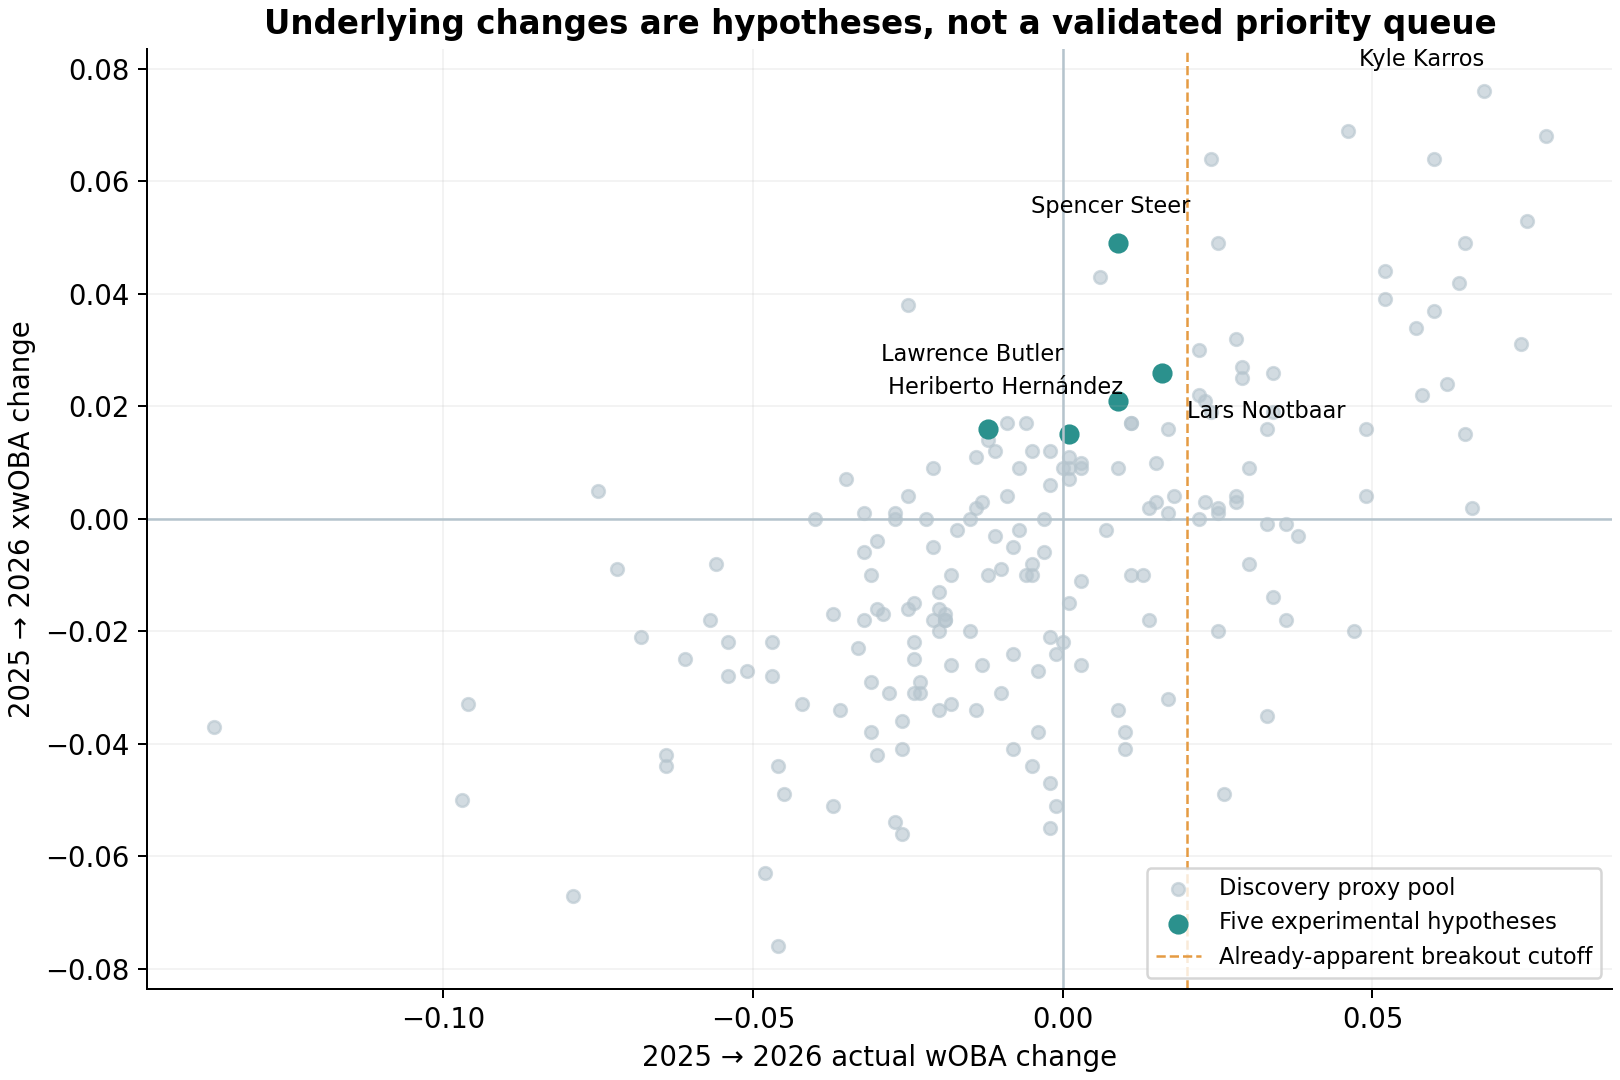

In [7]:
display(Markdown(loaded['brief']))
display(Image(data=base64.b64decode(loaded['charts']['signal_divergence.png'])))
print('[7/8] 완료: 한국어 결론·조사 목록을 표시했습니다.',flush=True)

## 7. Final report and result files

전체 HTML 보고서를 아래에 표시하며 현재 실행 폴더에 저장합니다. 파일이 내려받아지지 않으면 Colab 왼쪽 파일 탭에서 ZIP을 받을 수 있습니다. 미래 결과 칸은 pending으로 남깁니다.

[8/8] 전체 완료: 아래 보고서에 결과가 표시됩니다.
보고서와 ZIP을 위 링크 또는 실행 폴더에서 열 수 있습니다.



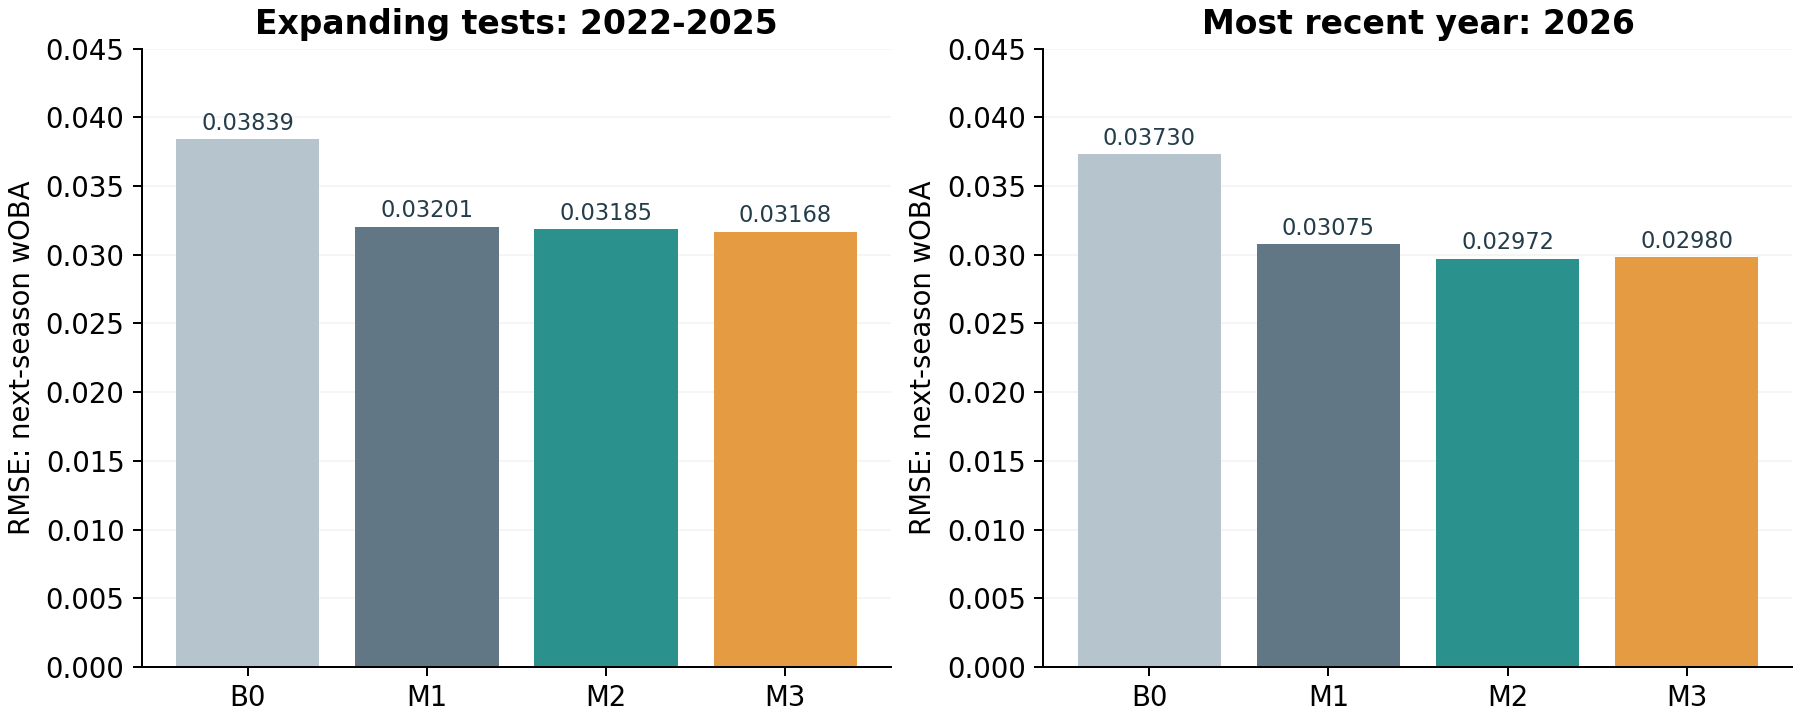
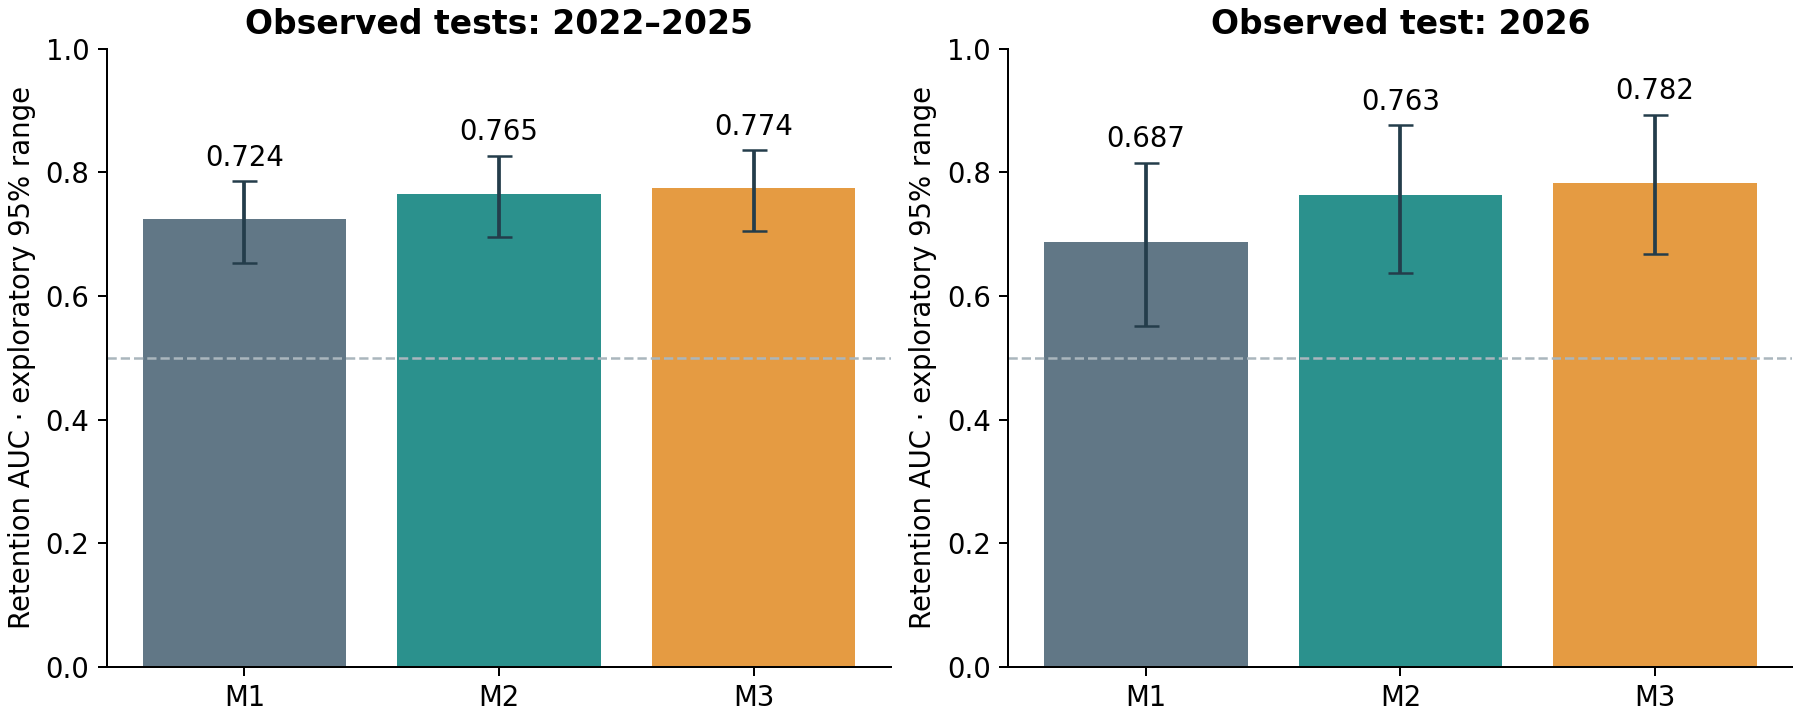
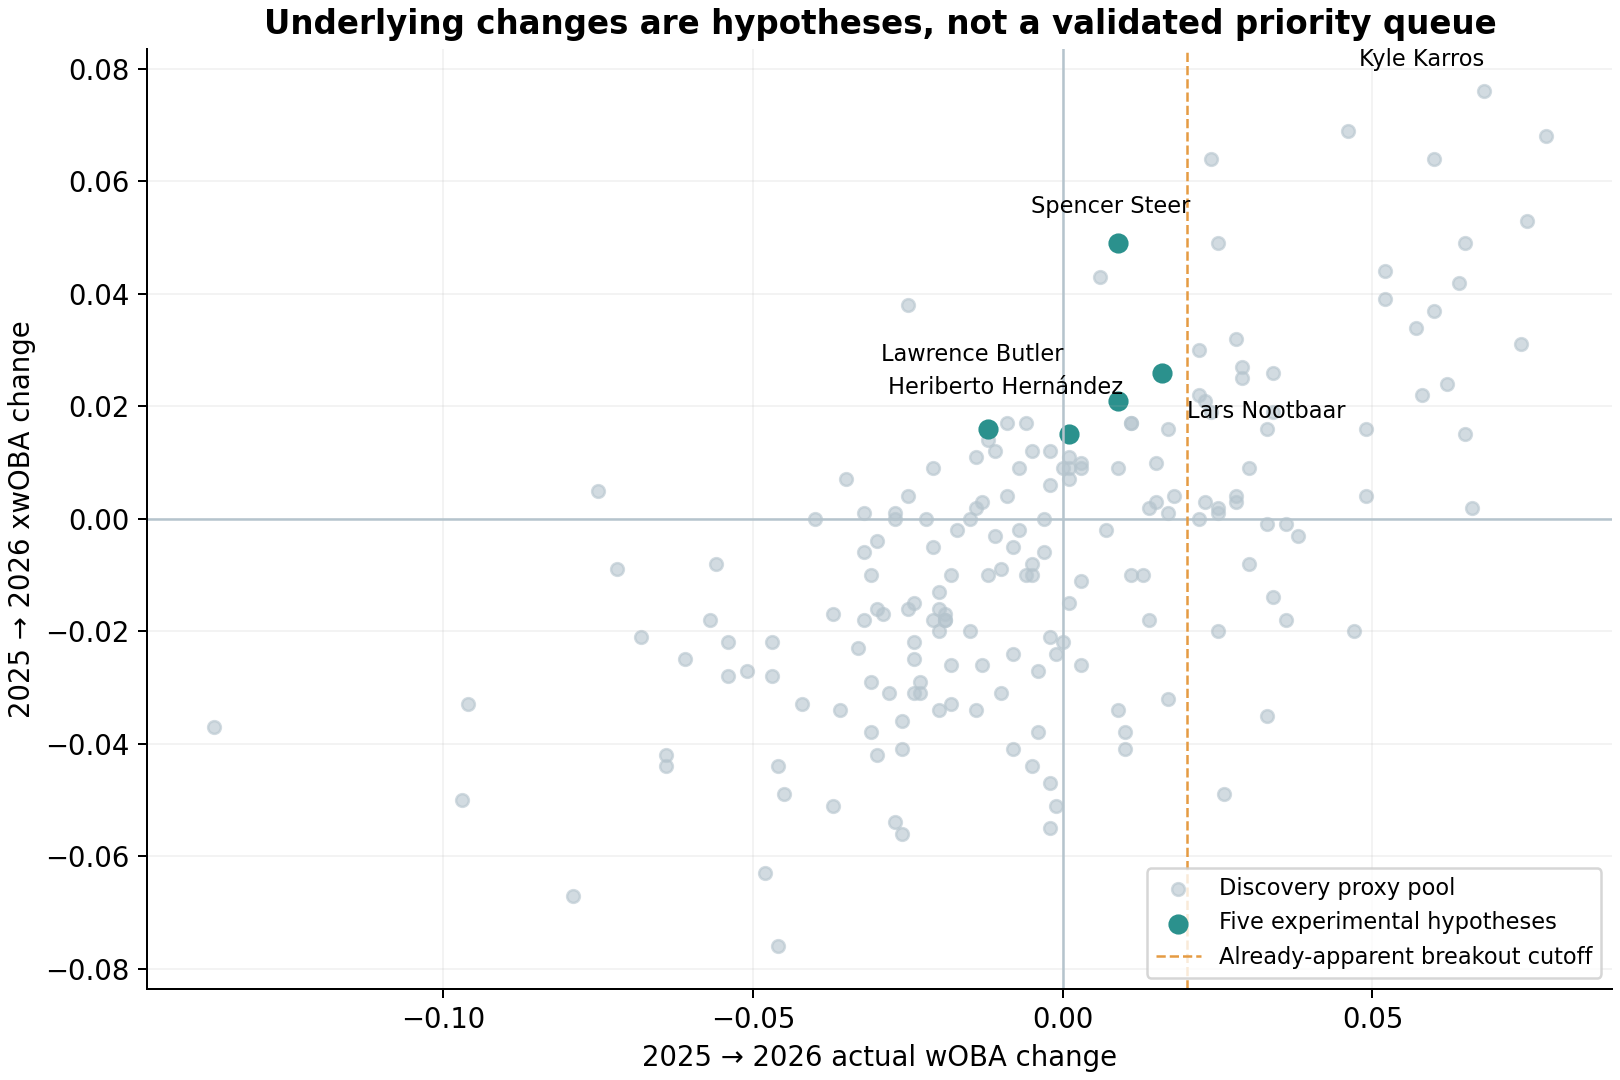

/workspace/scratch/6cd7d64c8c6b/revision_work/Before_the_Box_Score_2027/notebook_validation/before_the_box_score_2027_results/Signals_for_Next_Season_2027_Report.html

/workspace/scratch/6cd7d64c8c6b/revision_work/Before_the_Box_Score_2027/notebook_validation/Signals_for_Next_Season_2027_Notebook_Results.zip

In [8]:
result_dir=Path('before_the_box_score_2027_results');result_dir.mkdir(exist_ok=True)
for name,frame in {'model_metrics.csv':metrics,'breakout_diagnostics.csv':diagnostics,'decision_backtest.csv':backtest,'historical_predictions.csv':predictions,'2027_all_forecasts.csv':current,'2027_projection_top15.csv':watch,'2027_scouting_queue.csv':queue,'retention_sensitivity.csv':sens,'auc_intervals.csv':auc_ci,'paired_auc_intervals.csv':paired_ci,'scouting_policy_backtest.csv':policy_bt,'scouting_policy_names.csv':policy_names,'scouting_policy_summary.csv':policy_sum,'ranking_churn.csv':churn,'ranking_changes_names.csv':churn_names}.items():
    frame.to_csv(result_dir/name,index=False)
pending=queue[['queue_order','player_id','display_name','projected_woba_2027','created_at_utc']].copy()
pending['actual_pa_2027']=np.nan;pending['actual_woba_2027']=np.nan;pending['status']='pending'
pending.to_csv(result_dir/'2027_scouting_outcome_log.csv',index=False)
(result_dir/'2027_Decision_Brief_KO.md').write_text(loaded['brief'],encoding='utf-8')
report_path=result_dir/'Signals_for_Next_Season_2027_Report.html'
report_path.write_text(loaded['html'],encoding='utf-8')
pd.read_csv(io.StringIO(loaded['future_cohort'])).to_csv(result_dir/'2027_frozen_evaluation.csv',index=False)
(result_dir/'PROSPECTIVE_2027_PROTOCOL.md').write_text(loaded['prospective_protocol'],encoding='utf-8')
(result_dir/'snapshot_manifest.json').write_text(loaded['manifest'],encoding='utf-8')
(result_dir/'replay.json').write_text(json.dumps({'replayed_at_utc':datetime.now(timezone.utc).isoformat(),'frozen_at_utc':manifest['as_of_utc'],'gold_predictions_match':True,'future_results':'2027 pending'},indent=2),encoding='utf-8')
zip_path=Path('Signals_for_Next_Season_2027_Notebook_Results.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for path in sorted(result_dir.iterdir()):z.write(path,path.name)
print('[8/8] 전체 완료: 아래 보고서에 결과가 표시됩니다.',flush=True)
display(HTML('<style>'+loaded['style']+'</style><main>'+loaded['body']+'</main>'))
display(FileLink(str(report_path),result_html_prefix='HTML 보고서: '))
display(FileLink(str(zip_path),result_html_prefix='결과 ZIP: '))
try:
    from google.colab import files
except ImportError:
    print('보고서와 ZIP을 위 링크 또는 실행 폴더에서 열 수 있습니다.')
else:
    try:files.download(str(zip_path))
    except Exception:print('화면 결과는 완료됐습니다. Colab 왼쪽 파일 탭에서 ZIP을 받으세요.')